# Tugas: Clustering dengan DBSCAN, BIRCH, dan EM (Gaussian Mixture Model)

| Nama | NRP |
|------|-----|
| Zico Diego Rio Ramadhonny | 5054251023 |

## Deskripsi Tugas

Pada tugas ini, kalian akan melakukan clustering pada data pelanggan pusat perbelanjaan (*Mall Customer Segmentation*). Kalian akan membandingkan tiga pendekatan clustering:

1. **DBSCAN**, yang membentuk cluster berdasarkan kepadatan data dan dapat menandai data sebagai noise.
2. **BIRCH**, yang merangkum data ke dalam struktur pohon untuk membentuk subcluster.
3. **Expectation-Maximization (EM)** menggunakan **Gaussian Mixture Model (GMM)**, yang memodelkan data sebagai campuran beberapa distribusi probabilitas.

Dataset: [Mall Customer Segmentation Data di Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data).

Setiap baris mewakili satu pelanggan. Pada tugas ini, gunakan dua fitur agar hasilnya mudah divisualisasikan:
- `Annual Income (k$)`: pendapatan tahunan dalam ribuan dolar.
- `Spending Score (1-100)`: skor pengeluaran pelanggan.

**Penting:** `CustomerID` hanya merupakan identitas pelanggan, sehingga tidak digunakan sebagai fitur clustering. Kolom `Gender` juga tidak digunakan dalam eksperimen utama agar fokus tetap pada dua fitur numerik. Kolom tersebut boleh digunakan untuk interpretasi tambahan setelah model selesai, bukan sebagai input model.

## Tujuan Pembelajaran

- Melakukan eksplorasi dan preprocessing data sederhana.
- Memahami mengapa feature scaling diperlukan.
- Menjalankan DBSCAN, BIRCH, dan GMM dengan EM.
- Memahami parameter utama dan karakteristik setiap algoritma.
- Membandingkan hasil clustering menggunakan visualisasi dan metrik evaluasi internal.

## Persiapan Dataset

Unduh file CSV dari halaman Kaggle di atas. Letakkan file `Mall_Customers.csv` di folder yang sama dengan notebook ini. Nama file biasanya `Mall_Customers.csv`.

Langkah pengerjaan:
1. Persiapan dataset dan eksplorasi awal.
2. Preprocessing dan feature scaling.
3. Eksperimen DBSCAN.
4. Eksperimen BIRCH.
5. Eksperimen EM menggunakan Gaussian Mixture Model.
6. Evaluasi dan perbandingan model.
7. Analisis serta kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan:
# pandas, numpy, matplotlib, seaborn
# StandardScaler dari sklearn.preprocessing
# DBSCAN dari sklearn.cluster
# Birch dari sklearn.cluster
# GaussianMixture dari sklearn.mixture
# silhouette_score, davies_bouldin_score, calinski_harabasz_score dari sklearn.metrics

from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
import numpy as np, matplotlib.pyplot as plt, seaborn as sns, pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from sklearn.cluster import Birch, DBSCAN
from collections import defaultdict

In [2]:
# Muat Mall_Customers.csv ke dalam DataFrame bernama df.
# Jika file tidak ditemukan, periksa lokasi file dan nama file.
# Tampilkan 5 baris pertama, jumlah baris/kolom, tipe data, statistik deskriptif,
# jumlah missing value, dan jumlah baris duplikat.
df = pd.read_csv("Mall_Customers.csv")
display(df.info())
display(df.head(5))
display(df.describe())
display(df.isna().sum())
display(df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


None

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

np.int64(0)

array([[<Axes: title={'center': 'Annual Income (k$)'}>,
        <Axes: title={'center': 'Spending Score (1-100)'}>]], dtype=object)

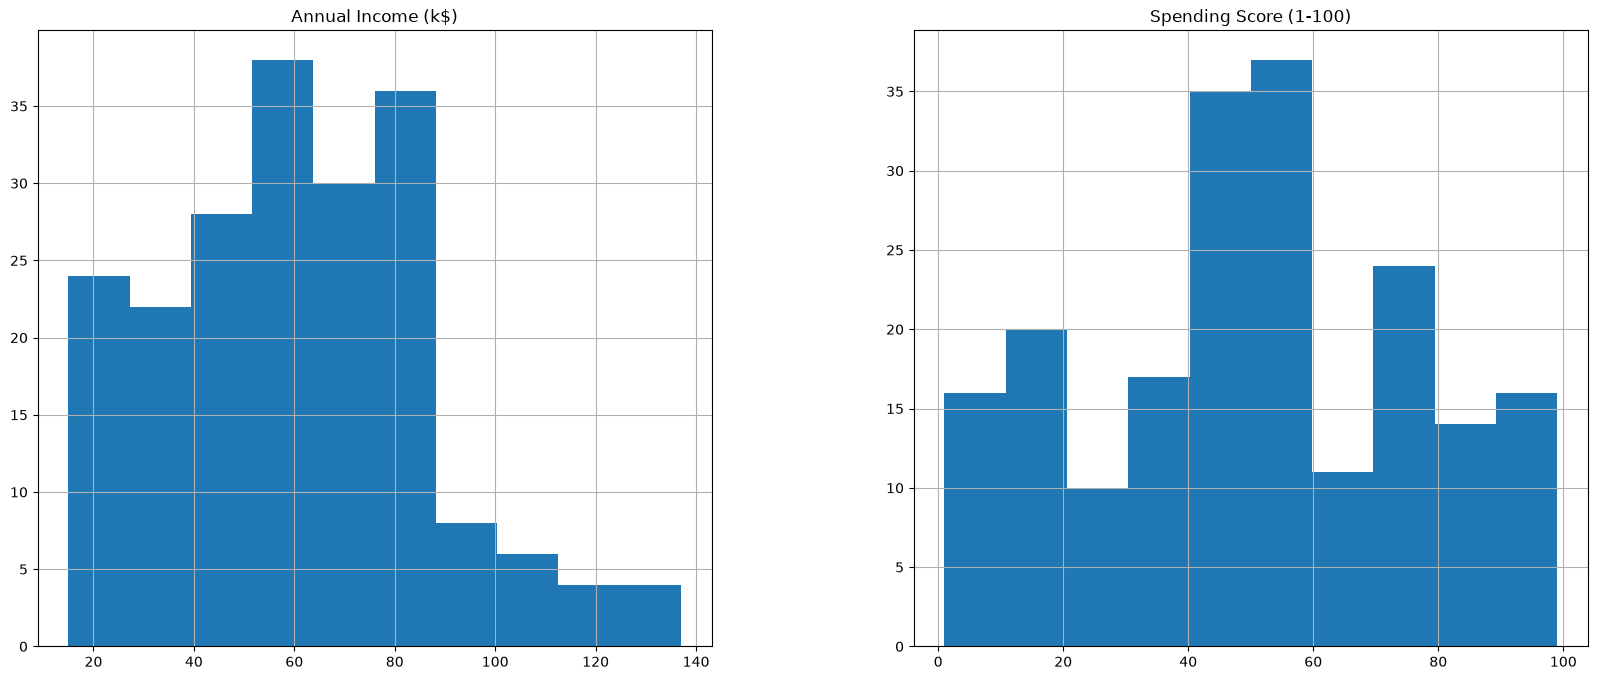

In [3]:
# Tampilkan distribusi Annual Income (k$) dan Spending Score (1-100)
# menggunakan histogram dan/atau boxplot.
# Amati rentang, bentuk distribusi, dan kemungkinan outlier.
num_df = df.select_dtypes(exclude=["str"]).drop(columns=["CustomerID", "Age"])
num_df.hist(figsize=(20, 8))

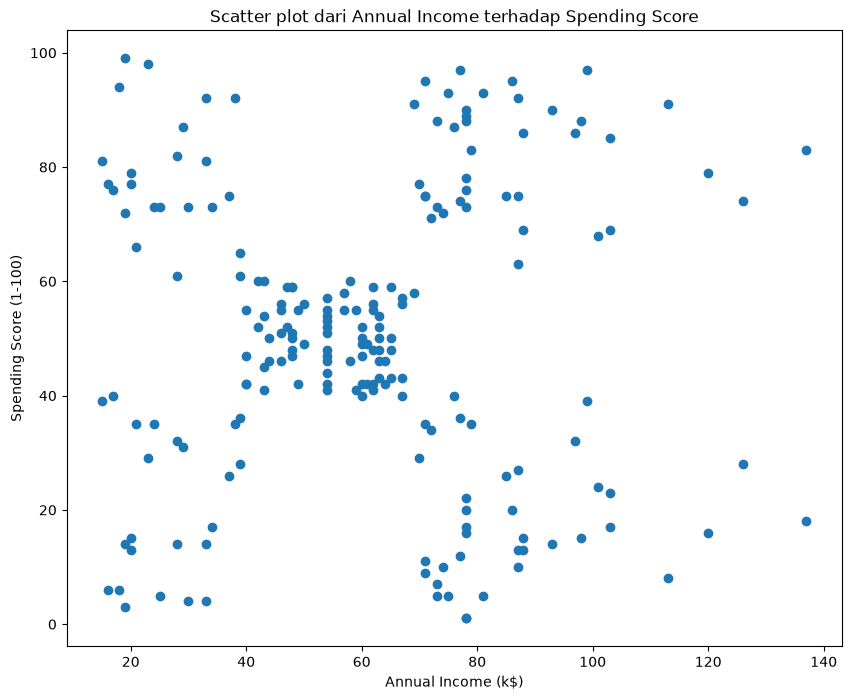

In [4]:
# Buat scatter plot dari Annual Income (k$) terhadap Spending Score (1-100).
# Jangan warnai berdasarkan label apa pun terlebih dahulu.
# Amati apakah terlihat kelompok-kelompok yang terpisah.

plt.figure(figsize=(10, 8))
plt.scatter(x=num_df["Annual Income (k$)"], y=num_df["Spending Score (1-100)"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Scatter plot dari Annual Income terhadap Spending Score")
plt.show()

## Pertanyaan EDA

Tuliskan pengamatan singkat:
- Apakah ada missing value atau baris duplikat?
- Bagaimana rentang pendapatan dan spending score?
- Apakah kedua fitur tampak memiliki kelompok yang terpisah?

Jawab:
- Pada initial EDA ini, tidak ditemukan data duplikat dan data hilang.
- Rentang pendapatan adalah [15, 137], sementara rentang spending score adalah [1, 99] menggunakan data yang ada.
- Secara visual, keduanya tampak membentuk kluster.

# 2. Preprocessing

In [5]:
# Periksa dan tangani missing value serta baris duplikat jika ditemukan.
# Karena CustomerID adalah identitas, jangan masukkan kolom tersebut ke fitur clustering.
# Pilih dua fitur numerik:
#   Annual Income (k$)
#   Spending Score (1-100)
# Simpan dalam DataFrame X.

X = df.drop(columns=["CustomerID", "Age", "Gender"])
display(X.isna().sum())
display(X.duplicated().sum())

print("No missing value. Proceeding to remove duplicates...")
X = X.loc[~X.duplicated()].reset_index(drop=True)
display(X.info())

Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

np.int64(4)

No missing value. Proceeding to remove duplicates...
<class 'pandas.DataFrame'>
RangeIndex: 196 entries, 0 to 195
Data columns (total 2 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Annual Income (k$)      196 non-null    int64
 1   Spending Score (1-100)  196 non-null    int64
dtypes: int64(2)
memory usage: 3.2 KB


None

In [6]:
# Lakukan feature scaling menggunakan StandardScaler.
# Simpan hasilnya sebagai X_scaled.
# Ubah hasil scaling menjadi DataFrame agar nama kolom tetap terlihat.
# Tampilkan beberapa baris X_scaled dan statistik deskriptifnya.
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame({
    "Annual Income (k$)": X_scaled[:, 0],
    "Spending Score (1-100)": X_scaled[:, 1]
})
display(X_scaled.head())
display(X_scaled.describe())

,Annual Income (k$),Spending Score (1-100)
0,-1.728800,-0.440412
1,-1.728800,1.193420
2,-1.690877,-1.724138
3,-1.690877,1.037817
4,-1.652954,-0.401512


,Annual Income (k$),Spending Score (1-100)
count,1.960000e+02,1.960000e+02
mean,-2.175131e-16,7.250436e-17
std,1.002561e+00,1.002561e+00
min,-1.728800e+00,-1.918642e+00
25%,-7.238324e-01,-6.057408e-01
50%,3.463405e-02,-1.250382e-02
75%,6.603688e-01,8.822142e-01
max,2.897845e+00,1.893635e+00


Perlu pakai scaling untuk distance-based clustering algorithm karena nilai yang tinggi bisa mendominasi perhitungan model, membuat data bernilai kecil kurang berpengaruh pada proses segmentasi.


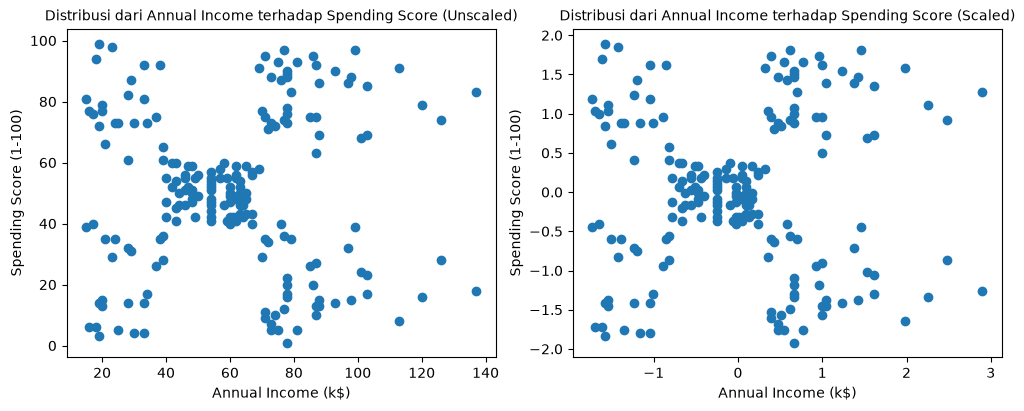

In [7]:
# Buat scatter plot sebelum dan sesudah scaling.
# Jelaskan mengapa scaling penting, terutama ketika algoritma menggunakan jarak
# atau mengasumsikan skala fitur yang sebanding.

print("Perlu pakai scaling untuk distance-based clustering algorithm karena nilai yang tinggi bisa mendominasi perhitungan model, membuat data bernilai kecil kurang berpengaruh pada proses segmentasi.")
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4), layout="constrained")
ax = ax.flatten()

for i, (X_df, scaled_str) in enumerate(zip([X, X_scaled], ["Unscaled", "Scaled"])):
    ax[i].scatter(x=X_df["Annual Income (k$)"], y=X_df["Spending Score (1-100)"])
    ax[i].set_title(f"Distribusi dari Annual Income terhadap Spending Score ({scaled_str})", fontsize=10)
    ax[i].set_xlabel("Annual Income (k$)")
    ax[i].set_ylabel("Spending Score (1-100)")
    
plt.show()

**Fitur yang digunakan:** `Annual Income (k$)` dan `Spending Score (1-100)`.

Tuliskan alasan pemilihan kedua fitur tersebut dan jelaskan mengapa `CustomerID` tidak digunakan.

Jawab: Fitur Annual Income dan Spending Score digunakan untuk clustering karena pada kasus ini, pengelompokkan didasarkan pada pendapatan per tahun dan pengeluaran. Fitur lain, seperti `CustomerID`, `Age`, dan `Gender`, tidak dimasukkan karena tidak memiliki pengaruh yang signifikan terhadap pengelompokkan (kecuali apabila pengelompokkan didasarkan pada umur atau gender).

# 3. Eksperimen DBSCAN

DBSCAN (*Density-Based Spatial Clustering of Applications with Noise*) membentuk cluster dari kumpulan titik yang padat. Titik yang tidak memenuhi kepadatan minimum dapat diberi label `-1`, yang berarti noise.

Parameter utama:
- `eps`: jarak maksimum agar dua titik dianggap berdekatan.
- `min_samples`: jumlah minimum titik di sekitar suatu titik agar titik tersebut dianggap sebagai titik inti (*core point*).

DBSCAN tidak perlu menentukan jumlah cluster di awal, tetapi hasilnya sensitif terhadap `eps` dan `min_samples`.

In [8]:
# Jalankan DBSCAN pada X_scaled.
# Mulai dengan eps dan min_samples yang masuk akal, misalnya eps=0.3 dan min_samples=5.
# Simpan label hasil clustering sebagai labels_dbscan.
# Catatan: nilai eps perlu dicoba dan dievaluasi, bukan dianggap pasti paling baik.

dbscan = DBSCAN(eps=0.3, min_samples=3)
dbscan.fit(X_scaled)
labels_dbscan = dbscan.labels_

In [9]:
# Tampilkan jumlah anggota setiap label hasil DBSCAN.
# Hitung jumlah cluster dengan tidak memasukkan label -1.
# Hitung juga jumlah titik noise (label -1).
noise_count = len(np.where(labels_dbscan == -1))
print("Jumlah noise:", noise_count)

valid_cluster = labels_dbscan[np.where(labels_dbscan > -1)]
cluster_component_count = defaultdict(int)
for num in valid_cluster:
    cluster_component_count[num.item()] += 1

cluster_count_df = pd.Series(cluster_component_count)
display(cluster_count_df)


Jumlah noise: 1


0     7
1    17
2     9
3     3
4     3
5    87
6    31
7    25
dtype: int64

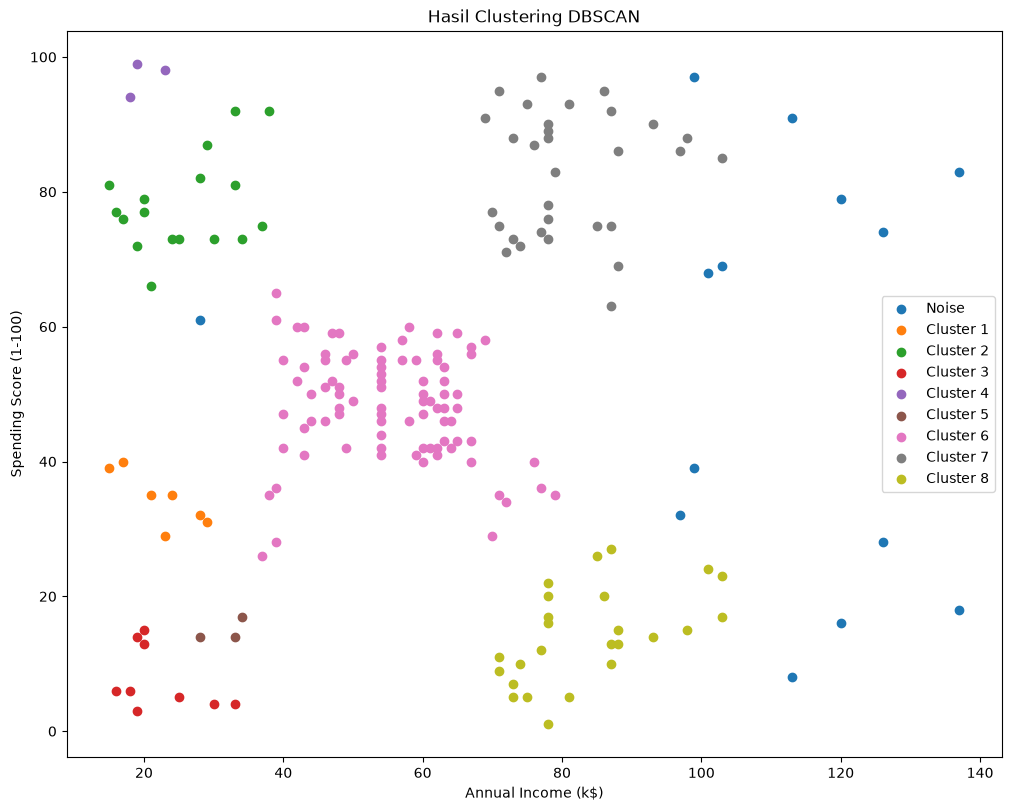

In [10]:
# Buat scatter plot hasil DBSCAN berdasarkan labels_dbscan.
# Gunakan X_scaled atau X untuk koordinat plot; untuk interpretasi, X (fitur asli)
# biasanya lebih mudah dipahami.
# Beri judul dan label sumbu yang jelas, serta pastikan noise dapat dibedakan.

unique_label = np.unique(labels_dbscan)
plt.figure(figsize=(10, 8), layout="constrained")

for i, label in enumerate(unique_label):
    curr_label_pts = X.loc[np.where(labels_dbscan == label)]
    num_label_str = f"Cluster {i}" if label != -1 else "Noise"
    plt.scatter(x=curr_label_pts["Annual Income (k$)"], y=curr_label_pts["Spending Score (1-100)"], label=num_label_str)
    
plt.title("Hasil Clustering DBSCAN")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

In [11]:
# Coba beberapa kombinasi eps dan min_samples.
# Buat tabel ringkasan yang berisi eps, min_samples, jumlah cluster (tanpa noise),
# jumlah noise, dan Silhouette Score jika metrik tersebut valid.
# Hindari menghitung silhouette jika hasilnya hanya satu cluster atau semua titik noise.
MAX_EPS = 1000
MAX_SAMPLES = 100

range_eps = [i/1000 for i in range(1, MAX_EPS+1)]
sample_range = [i for i in range(1, MAX_SAMPLES+1)]

dbscan_result_dict = {
    "eps": [],
    "min_samples": [],
    "n_clusters": [],
    "silhouette_score": []
}
for eps in range_eps:
    for sample in sample_range:
        curr_dbscan = DBSCAN(eps=eps, min_samples=sample).fit(X_scaled)
        not_noise_ids = np.where(curr_dbscan.labels_ > -1)
        n_clusters = np.unique(curr_dbscan.labels_[not_noise_ids])

        curr_silhouette_score = -float("inf")
        if len(n_clusters) > 1 and len(n_clusters) != len(X_scaled):
            curr_silhouette_score = silhouette_score(X_scaled.loc[not_noise_ids], curr_dbscan.labels_[not_noise_ids])
            
        dbscan_result_dict["eps"].append(eps)
        dbscan_result_dict["min_samples"].append(sample)
        dbscan_result_dict["silhouette_score"].append(curr_silhouette_score)
        dbscan_result_dict["n_clusters"].append(len(n_clusters))
        
dbscan_df = pd.DataFrame(dbscan_result_dict).sort_values("silhouette_score", ascending=False).reset_index(drop=True)
dbscan_df["silhouette_score"] = dbscan_df["silhouette_score"].map(lambda x: x if x > -float("inf") else "-")
display(dbscan_df)

,eps,min_samples,n_clusters,silhouette_score
0,0.045,3,5,0.788672
1,0.044,3,5,0.788672
2,0.039,3,5,0.788672
3,0.052,3,5,0.788672
4,0.054,3,5,0.788672
...,...,...,...,...
99995,0.375,20,1,-
99996,0.375,19,1,-
99997,0.375,18,1,-
99998,0.375,17,1,-


In [12]:
print("Kombinasi parameter (eps dan min_samples) yang menghasilkan satu kluster besar (tidak termasuk noise):")
display(dbscan_df.loc[dbscan_df["n_clusters"] == 1])

print("Kombinasi parameter (eps dan min_samples) yang hanya menghasilkan noise:")
display(dbscan_df.loc[dbscan_df["n_clusters"] == 0])

Kombinasi parameter (eps dan min_samples) yang menghasilkan satu kluster besar (tidak termasuk noise):


,eps,min_samples,n_clusters,silhouette_score
7555,0.690,63,1,-
7558,0.691,37,1,-
7561,0.690,37,1,-
7565,0.691,38,1,-
7568,0.690,64,1,-
...,...,...,...,...
99995,0.375,20,1,-
99996,0.375,19,1,-
99997,0.375,18,1,-
99998,0.375,17,1,-


Kombinasi parameter (eps dan min_samples) yang hanya menghasilkan noise:


,eps,min_samples,n_clusters,silhouette_score
7556,0.690,97,0,-
7557,0.683,93,0,-
7559,0.683,94,0,-
7560,0.683,86,0,-
7562,0.690,78,0,-
...,...,...,...,...
99988,0.374,100,0,-
99989,0.374,99,0,-
99990,0.374,98,0,-
99991,0.374,97,0,-


### Analisis DBSCAN

- Apa pengaruh kenaikan `eps` terhadap jumlah cluster dan noise?
- Apa pengaruh `min_samples`?
- Apakah ada kombinasi parameter yang menghasilkan satu cluster besar atau terlalu banyak noise?

Jawab:
- Parameter `eps` menyatakan jarak maksimum agar sebuah titik dianggap bertetangga. Semakin besar nilai `eps`, maka jarak maksimum menjadi lebih besar, membuat lebih banyak titik berkumpul menjadi sebuah kluster.
- Parameter `min_samples` menyatakan banyak titik tetangga minimum agar sebuah titik dianggap sebagai _core point_. Semakin besar nilai `min_samples`, maka sebuah titik memerlukan lebih banyak titik tetangga untuk dinyatakan sebagai _core point_.
- Ada di cell atas.

# 4. Eksperimen BIRCH

BIRCH (*Balanced Iterative Reducing and Clustering using Hierarchies*) membangun struktur pohon ringkasan cluster. Parameter `threshold` mengatur seberapa dekat titik harus berada agar dapat digabungkan dalam subcluster. `n_clusters` menentukan jumlah cluster akhir jika diberikan.

Berbeda dari DBSCAN, BIRCH tidak memberi label noise secara eksplisit.

In [13]:
# Latih model Birch pada X_scaled.
# Coba threshold awal, misalnya 0.5, dan n_clusters=5.
# Simpan label hasil clustering sebagai labels_birch.
# Catatan: jumlah cluster akhir dapat berubah sesuai parameter yang digunakan.

birch = Birch(threshold=0.5, n_clusters=5).fit(X_scaled)
labels_birch = birch.labels_

In [14]:
# Tampilkan jumlah anggota setiap cluster BIRCH.
# Tampilkan juga jumlah cluster yang terbentuk.
cluster_component_count = defaultdict(int)
for num in labels_birch:
    cluster_component_count[num.item()] += 1

cluster_count_df = pd.Series(cluster_component_count)
display(cluster_count_df)
print("Jumlah kluster:", len(cluster_count_df))

3     24
4     22
1    108
0     35
2      7
dtype: int64

Jumlah kluster: 5


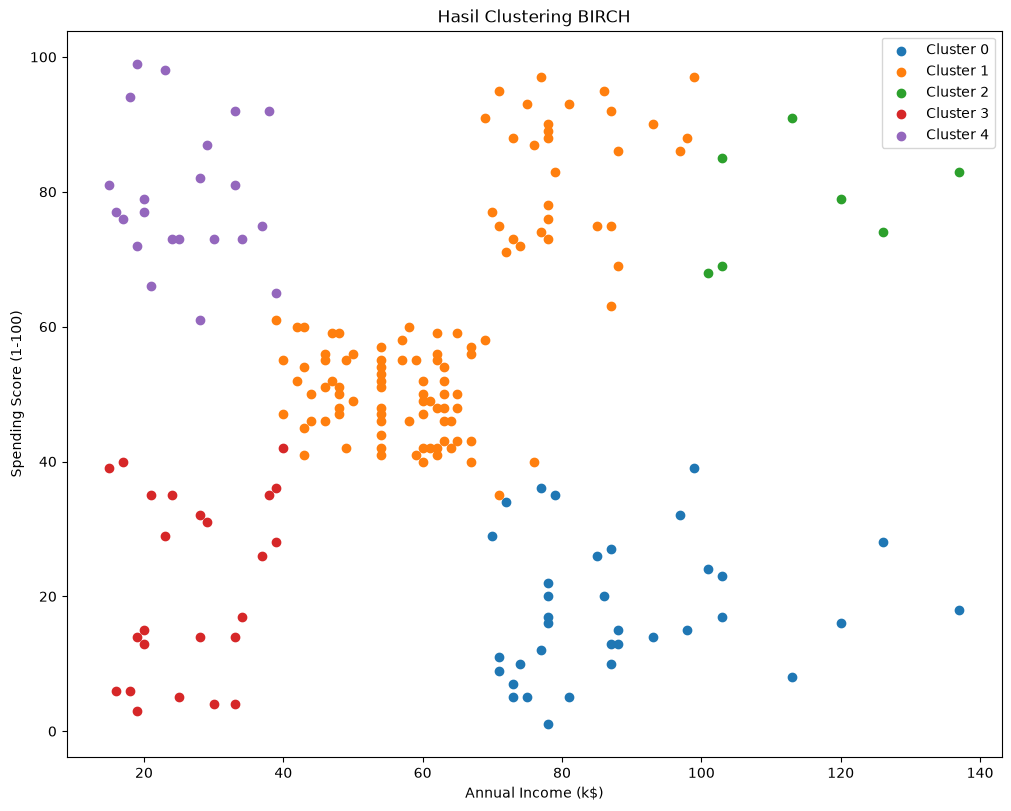

In [15]:
# Buat scatter plot hasil BIRCH pada ruang fitur asli X.
# Warnai titik berdasarkan labels_birch.

unique_label = np.unique(labels_birch)
plt.figure(figsize=(10, 8), layout="constrained")

for i, label in enumerate(unique_label):
    curr_label_pts = X.loc[np.where(labels_birch == label)]
    num_label_str = f"Cluster {i}"
    plt.scatter(x=curr_label_pts["Annual Income (k$)"], y=curr_label_pts["Spending Score (1-100)"], label=num_label_str)
    
plt.title("Hasil Clustering BIRCH")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()

In [16]:
# Bandingkan beberapa nilai threshold (misalnya 0.3, 0.5, 0.7, 1.0)
# dengan jumlah cluster akhir yang sama jika memungkinkan.
# Buat tabel berisi threshold, jumlah cluster, dan Silhouette Score bila valid.
from IPython.display import clear_output

MAX_THRESH_INTERPOLATE = 100000
MAX_CLUSTER = len(X_scaled)

range_thresh = [i/1000 for i in range(1, MAX_THRESH_INTERPOLATE+1)]
cluster_range = [len(X_scaled)] # [i for i in range(1, MAX_SAMPLES+1)]

birch_result_dict = {
    "thresh": [],
    "n_clusters": [],
    "cluster_found": [],
    "silhouette_score": [],
}
for thresh in range_thresh:
    for cluster in cluster_range:
        try:
            curr_birch = Birch(threshold=thresh, n_clusters=cluster).fit(X_scaled)
        except ValueError:
            continue
        
        n_clusters = np.unique(curr_birch.labels_)

        curr_silhouette_score = -float("inf")
        if len(n_clusters) > 1 and len(n_clusters) != len(X_scaled):
            curr_silhouette_score = silhouette_score(X_scaled, curr_birch.labels_)
            
        birch_result_dict["thresh"].append(thresh)
        birch_result_dict["n_clusters"].append(cluster)
        birch_result_dict["silhouette_score"].append(curr_silhouette_score)
        birch_result_dict["cluster_found"].append(len(n_clusters))

clear_output() 
birch_df = pd.DataFrame(birch_result_dict).sort_values("silhouette_score", ascending=False).reset_index(drop=True)
birch_df["silhouette_score"] = birch_df["silhouette_score"].map(lambda x: x if x > -float("inf") else "-")
display(birch_df)

,thresh,n_clusters,cluster_found,silhouette_score
0,0.634,196,7,0.540232
1,0.635,196,7,0.540232
2,0.650,196,7,0.540232
3,0.651,196,7,0.540232
4,0.652,196,7,0.540232
...,...,...,...,...
99995,34.250,196,1,-
99996,34.249,196,1,-
99997,34.248,196,1,-
99998,34.247,196,1,-


### Analisis BIRCH

- Apa yang terjadi pada jumlah cluster ketika `threshold` diperbesar?
- Apa perbedaan BIRCH dan DBSCAN dalam menangani titik yang berada jauh dari kelompok utama?
- Apakah hasil BIRCH berubah ketika `n_clusters` ditentukan?

Jawab:
- Ketika `threshold` diperbesar, jumlah kluster menyusut karena radius subkluster juga menjadi lebih luas, membuat lebih banyak titik terkumpul pada satu kelompok.
- DBSCAN menganggap titik yang jauh tersebut sebagai border point ketika masih dalam jangkauan core point atau noise, sedangkan BIRCH menganggap semua titik adalah bagian dari kluster atau subkluster.
- Apabila nilai `n_clusters` ditentukan, jumlah kluster akan disesuaikan dengan penentuan tersebut meskipun jumlah kluster yang sebenarnya lebih banyak.

# 5. Eksperimen EM dengan Gaussian Mixture Model

Expectation-Maximization (EM) adalah algoritma iteratif untuk mengestimasi parameter model probabilistik. Dalam praktikum ini, EM digunakan untuk melatih **Gaussian Mixture Model (GMM)**.

GMM menganggap data berasal dari campuran beberapa distribusi Gaussian. Untuk setiap titik, GMM menghasilkan probabilitas keanggotaan pada setiap komponen, kemudian label cluster ditentukan dari komponen dengan probabilitas terbesar.

Parameter utama:
- `n_components`: jumlah distribusi Gaussian/cluster yang dimodelkan.
- `covariance_type`: bentuk matriks kovarians yang digunakan.
- `random_state`: agar hasil eksperimen dapat diulang.

In [17]:
# Latih GaussianMixture pada X_scaled menggunakan EM.
# Mulai dengan n_components=5, covariance_type='full', dan random_state=42.
# Simpan label hasil prediksi sebagai labels_gmm.

gmm = GaussianMixture(n_components=5, covariance_type="full", random_state=42)
gmm.fit(X_scaled)
labels_gmm = gmm.predict(X_scaled)
print("Jumlah kluster GMM:", len(np.unique(labels_gmm)))
print("Label cluster:", np.unique(labels_gmm))


Jumlah kluster GMM: 5
Label cluster: [0 1 2 3 4]


In [18]:
# Tampilkan jumlah anggota setiap cluster GMM.
# Gunakan predict_proba untuk melihat probabilitas keanggotaan tiap titik.
# Tampilkan beberapa baris probabilitas dan periksa apakah ada titik dengan
# keanggotaan yang relatif tidak pasti.

cluster_component_count = defaultdict(int)
for num in labels_gmm:
    cluster_component_count[num] += 1
cluster_count_df = pd.Series(cluster_component_count).sort_index()
display(cluster_count_df)

probability_df = pd.DataFrame(
    gmm.predict_proba(X_scaled),
    columns=[f"Comp_{i}" for i in range(gmm.n_components)]
)
display(probability_df.head())

uncertain_score = probability_df.max(axis=1)
print("10 titik dengan keanggotaan paling tidak pasti:")
display(uncertain_score.sort_values().head(10))


0    82
1    32
2    21
3    38
4    23
dtype: int64

,Comp_0,Comp_1,Comp_2,Comp_3,Comp_4
0,8.694323e-06,1.691331e-07,9.580882e-04,9.171412e-09,0.999033
1,1.027239e-05,4.472072e-22,9.998273e-01,1.582852e-04,0.000004
2,4.367452e-20,2.254552e-04,1.557449e-12,3.687219e-19,0.999775
3,7.122590e-05,3.533226e-20,9.997638e-01,1.435241e-04,0.000021
4,3.821440e-05,1.541783e-07,1.595429e-03,1.947770e-08,0.998366


10 titik dengan keanggotaan paling tidak pasti:


122    0.579412
48     0.621936
27     0.717033
156    0.728757
45     0.800285
54     0.810262
143    0.881915
129    0.901717
47     0.902695
41     0.927828
dtype: float64

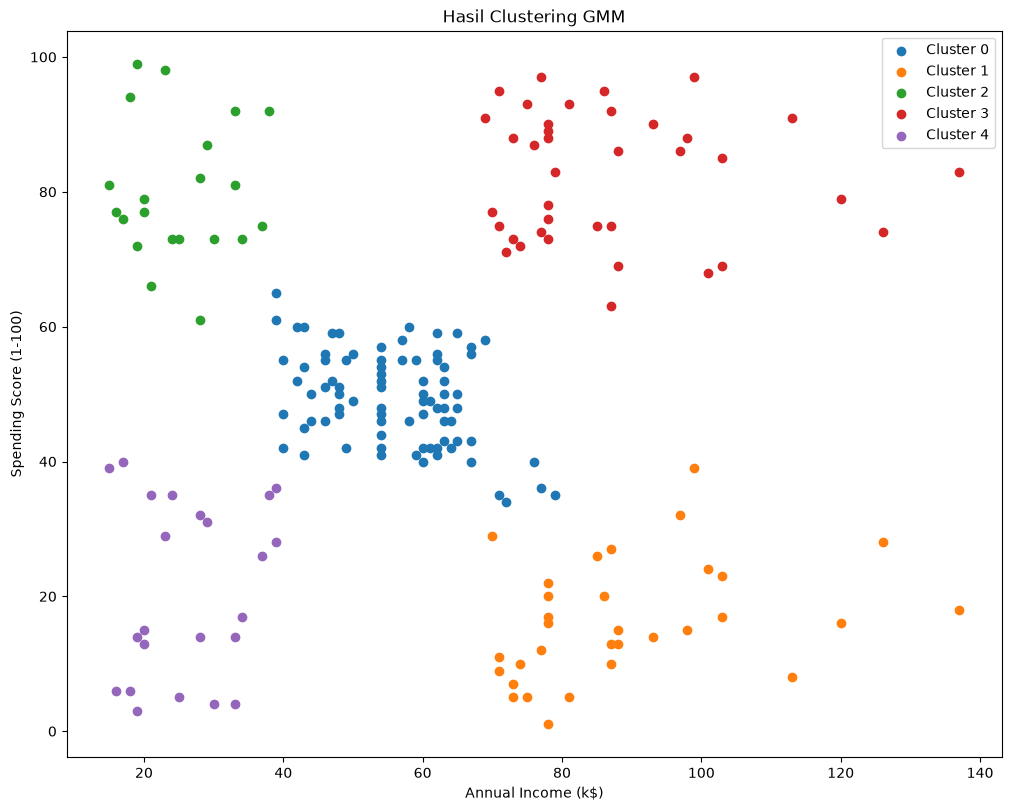

In [19]:
# Buat scatter plot hasil GMM pada ruang fitur asli X.
# Warnai titik berdasarkan labels_gmm.

unique_label = np.unique(labels_gmm)
plt.figure(figsize=(10, 8), layout="constrained")

for label in unique_label:
    curr_label_pts = X.loc[np.where(labels_gmm == label)]
    plt.scatter(
        x=curr_label_pts["Annual Income (k$)"],
        y=curr_label_pts["Spending Score (1-100)"],
        label=f"Cluster {label}"
    )

plt.title("Hasil Clustering GMM")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend()
plt.show()


In [20]:
# Bandingkan beberapa nilai n_components (misalnya 2 sampai 8).
# Catat Silhouette Score dan BIC untuk setiap model.
# BIC yang lebih rendah menunjukkan keseimbangan model dan kecocokan data yang lebih baik
# menurut kriteria BIC, tetapi tetap perlu dipertimbangkan bersama visualisasi dan konteks.

gmm_result_dict = {
    "n_components": [],
    "bic": [],
    "silhouette_score": []
}

for n_components in range(2, 9):
    model = GaussianMixture(n_components=n_components, covariance_type="full", random_state=42)
    labels = model.fit_predict(X_scaled)
    bic_value = model.bic(X_scaled)
    unique_labels = np.unique(labels)

    sil_value = np.nan
    if len(unique_labels) > 1 and len(unique_labels) < len(X_scaled):
        sil_value = silhouette_score(X_scaled, labels)

    gmm_result_dict["n_components"].append(n_components)
    gmm_result_dict["bic"].append(bic_value)
    gmm_result_dict["silhouette_score"].append(sil_value)

gmm_df = pd.DataFrame(gmm_result_dict).sort_values("bic").reset_index(drop=True)
display(gmm_df)


,n_components,bic,silhouette_score
0,5,1035.245171,0.556498
1,6,1047.756152,0.529215
2,4,1056.693141,0.461788
3,8,1063.644870,0.470953
4,7,1066.235647,0.515591
5,3,1130.005426,0.431092
6,2,1131.477263,0.380791


### Analisis EM/GMM

- Apa arti probabilitas keanggotaan yang dihasilkan GMM?
- Apa yang terjadi ketika `n_components` diubah?
- Mengapa jumlah cluster GMM perlu ditentukan sebelum model dilatih?
- Apakah model dengan Silhouette Score tertinggi juga memiliki BIC terendah?

Jawab:
- Probabilitas keanggotaan adalah peluang tiap titik termasuk ke dalam tiap komponen Gaussian. GMM tidak memberi label tegas secara langsung, melainkan nilai probabilitas yang menunjukkan seberapa kuat suatu titik menjadi anggota masing-masing cluster.
- Saat `n_components` diubah, model akan mencoba menyesuaikan jumlah distribusi Gaussian yang menggambarkan data. Jika terlalu kecil, data kompleks dapat diwakili terlalu umum; jika terlalu besar, model dapat overfit atau membagi cluster nyata menjadi sub-kluster.
- Jumlah cluster GMM harus ditentukan di awal karena GMM bekerja dengan campuran distribusi yang jumlah komponennya sudah ditetapkan sebelum estimasi parameter dilakukan melalui EM.
- Tidak selalu. Pada dataset ini, `n_components=5` memiliki Silhouette Score tertinggi, dan BIC juga paling rendah di antara nilai yang diuji. Ini menunjukkan bahwa model yang paling baik secara keseimbangan kualitas dan kompleksitas sesuai dengan data yang diamati.


# 6. Evaluasi dan Perbandingan Model

Bandingkan model DBSCAN, BIRCH, dan GMM menggunakan:
- Jumlah cluster yang terbentuk.
- Jumlah titik noise, khusus untuk DBSCAN.
- Silhouette Score: semakin tinggi biasanya semakin baik.
- Davies-Bouldin Index: semakin rendah biasanya semakin baik.
- Calinski-Harabasz Score: semakin tinggi biasanya semakin baik.

Metrik internal perlu ditafsirkan dengan hati-hati. Untuk DBSCAN, keluarkan titik noise dari perhitungan metrik jika ingin menilai kualitas cluster yang terbentuk. Metrik tidak dapat dihitung secara bermakna jika hasilnya hanya satu cluster atau setiap titik menjadi cluster sendiri.

In [21]:
# Buat fungsi evaluasi yang menerima X_scaled dan label clustering.
# Untuk DBSCAN, hitung metrik pada titik non-noise saja.
# Pastikan metrik hanya dihitung jika terdapat setidaknya 2 cluster
# dan jumlah cluster lebih kecil daripada jumlah titik yang dievaluasi.

def evaluate_clustering(X_data, labels, model_name="model"):
    labels = np.asarray(labels)
    if model_name == "DBSCAN":
        valid_mask = labels != -1
    else:
        valid_mask = np.ones(len(labels), dtype=bool)

    if valid_mask.sum() < 2:
        return {
            "model": model_name,
            "n_clusters": len(np.unique(labels[valid_mask])),
            "noise": int((labels == -1).sum()) if model_name == "DBSCAN" else 0,
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan,
        }

    unique_labels = np.unique(labels[valid_mask])
    if len(unique_labels) < 2 or len(unique_labels) >= valid_mask.sum():
        return {
            "model": model_name,
            "n_clusters": len(unique_labels),
            "noise": int((labels == -1).sum()) if model_name == "DBSCAN" else 0,
            "silhouette": np.nan,
            "davies_bouldin": np.nan,
            "calinski_harabasz": np.nan,
        }

    X_valid = X_data.loc[valid_mask].reset_index(drop=True)
    labels_valid = labels[valid_mask]

    return {
        "model": model_name,
        "n_clusters": len(unique_labels),
        "noise": int((labels == -1).sum()) if model_name == "DBSCAN" else 0,
        "silhouette": silhouette_score(X_valid, labels_valid),
        "davies_bouldin": davies_bouldin_score(X_valid, labels_valid),
        "calinski_harabasz": calinski_harabasz_score(X_valid, labels_valid),
    }


In [22]:
# Evaluasi hasil terbaik dari DBSCAN, BIRCH, dan GMM.
# Sajikan ringkasan dalam satu DataFrame/tabel:
# model, jumlah cluster, jumlah noise, silhouette, Davies-Bouldin, Calinski-Harabasz.
# Untuk BIRCH dan GMM, jumlah noise dapat ditulis 0 atau N/A karena algoritma
# tersebut tidak menandai noise secara eksplisit.

summary_rows = [
    evaluate_clustering(X_scaled, labels_dbscan, "DBSCAN"),
    evaluate_clustering(X_scaled, labels_birch, "BIRCH"),
    evaluate_clustering(X_scaled, labels_gmm, "GMM"),
]
summary_df = pd.DataFrame(summary_rows)
summary_df = summary_df[["model", "n_clusters", "noise", "silhouette", "davies_bouldin", "calinski_harabasz"]]
display(summary_df.sort_values("silhouette", ascending=False).reset_index(drop=True))


,model,n_clusters,noise,silhouette,davies_bouldin,calinski_harabasz
0,GMM,5,0,0.556498,0.572126,243.264864
1,DBSCAN,8,14,0.505998,0.612384,182.921678
2,BIRCH,5,0,0.415510,0.697109,119.939300


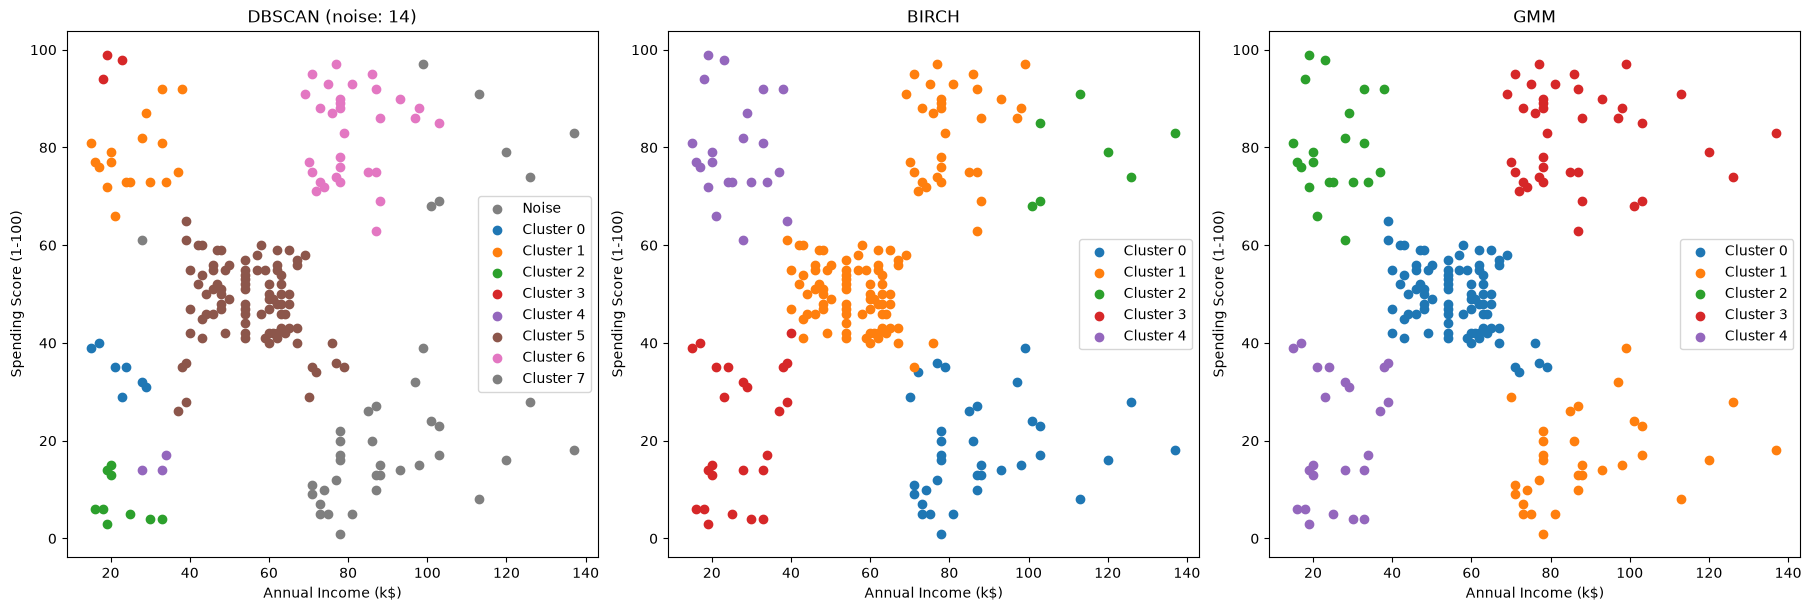

In [23]:
# Buat tiga scatter plot dalam satu baris subplot:
# DBSCAN, BIRCH, dan GMM.
# Gunakan koordinat dari fitur asli X dan warna berdasarkan label cluster.
# Beri judul yang menunjukkan algoritma dan jumlah cluster/noise.

fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout="constrained")
algorithms = [
    ("DBSCAN", labels_dbscan, "DBSCAN"),
    ("BIRCH", labels_birch, "BIRCH"),
    ("GMM", labels_gmm, "GMM")
]

for ax, (name, labels, label_title) in zip(axes, algorithms):
    for label in np.unique(labels):
        current_points = X.loc[np.where(labels == label)]
        if name == "DBSCAN" and label == -1:
            ax.scatter(current_points["Annual Income (k$)"], current_points["Spending Score (1-100)"], color="gray", label="Noise")
        else:
            ax.scatter(current_points["Annual Income (k$)"], current_points["Spending Score (1-100)"], label=f"Cluster {label}")
    noise_note = " (noise: 14)" if name == "DBSCAN" else ""
    ax.set_title(f"{label_title}{noise_note}")
    ax.set_xlabel("Annual Income (k$)")
    ax.set_ylabel("Spending Score (1-100)")

axes[0].legend()
axes[1].legend()
axes[2].legend()
plt.show()


In [35]:
# Buat profil cluster pada fitur asli.
# Untuk setiap algoritma, tampilkan jumlah anggota serta median dan rata-rata
# Annual Income (k$) dan Spending Score (1-100) untuk setiap cluster.
# Untuk DBSCAN, analisis label -1 (noise) secara terpisah.

cluster_profiles = []
for name, labels in [("DBSCAN", labels_dbscan), ("BIRCH", labels_birch), ("GMM", labels_gmm)]:
    cluster_df = X.copy()
    cluster_df["cluster"] = labels

    if name == "DBSCAN":
        noise_df = cluster_df[cluster_df["cluster"] == -1]
        if not noise_df.empty:
            noise_summary = {
                "model": "DBSCAN",
                "cluster": "Noise",
                "n": len(noise_df),
                "income_median": noise_df["Annual Income (k$)"].median(),
                "income_mean": noise_df["Annual Income (k$)"].mean(),
                "spending_median": noise_df["Spending Score (1-100)"].median(),
                "spending_mean": noise_df["Spending Score (1-100)"].mean(),
            }
            cluster_profiles.append(noise_summary)

    summary = cluster_df[cluster_df["cluster"] != -1].groupby("cluster").agg(
        n=("cluster", "size"),
        income_median=("Annual Income (k$)", "median"),
        income_mean=("Annual Income (k$)", "mean"),
        spending_median=("Spending Score (1-100)", "median"),
        spending_mean=("Spending Score (1-100)", "mean")
    ).reset_index()
    summary["model"] = name
    cluster_profiles.append(summary)

dbscan_noise_dict = cluster_profiles.pop(0)
cluster_profiles[0] = pd.concat([cluster_profiles[0], pd.DataFrame(dbscan_noise_dict, index=[0])])
for profile in cluster_profiles:
    model_name = profile["model"].unique()[0]
    print(f"Profil {model_name}:")
    display(profile)

Profil DBSCAN:


,cluster,n,income_median,income_mean,spending_median,spending_mean,model
0,0,7,23.0,22.428571,35.0,34.428571,DBSCAN
1,1,17,25.0,25.823529,77.0,78.176471,DBSCAN
2,2,9,20.0,22.222222,6.0,7.777778,DBSCAN
3,3,3,19.0,20.000000,98.0,97.000000,DBSCAN
4,4,3,33.0,31.666667,14.0,15.000000,DBSCAN
5,5,87,54.0,55.275862,49.0,48.275862,DBSCAN
6,6,31,78.0,80.806452,86.0,82.806452,DBSCAN
7,7,25,81.0,83.640000,14.0,14.280000,DBSCAN
0,Noise,14,113.0,108.500000,64.5,54.500000,DBSCAN


Profil BIRCH:


,cluster,n,income_median,income_mean,spending_median,spending_mean,model
0,0,35,85.0,88.028571,16.0,18.057143,BIRCH
1,1,108,62.0,62.777778,54.5,59.379630,BIRCH
2,2,7,113.0,114.714286,79.0,78.428571,BIRCH
3,3,24,26.5,26.875000,21.5,21.791667,BIRCH
4,4,22,24.5,25.727273,77.0,79.363636,BIRCH


Profil GMM:


,cluster,n,income_median,income_mean,spending_median,spending_mean,model
0,0,82,57.0,55.926829,49.5,49.341463,GMM
1,1,32,86.5,89.156250,15.5,16.468750,GMM
2,2,21,24.0,25.095238,77.0,80.047619,GMM
3,3,38,80.0,86.947368,84.0,82.315789,GMM
4,4,23,25.0,26.304348,17.0,20.913043,GMM


### Ringkasan Perbandingan

Lengkapi tabel atau tuliskan rangkuman berdasarkan hasil eksperimen:

| Aspek | DBSCAN | BIRCH | EM/GMM |
|---|---|---|---|
| Perlu menentukan jumlah cluster di awal? | Tidak | Tidak wajib; `n_clusters` opsional | Ya |
| Dapat memberi label noise secara eksplisit? | Ya | Tidak | Tidak |
| Parameter yang paling memengaruhi hasil | `eps`, `min_samples` | `threshold`, `n_clusters` | `n_components`, `covariance_type` |
| Bentuk cluster yang dapat dimodelkan | Cluster dengan kepadatan dan pola tidak beraturan | Cluster padat/terstruktur dengan peringkasan hierarki | Cluster berbentuk Gaussian/elliptic |
| Kelebihan | Sangat cocok untuk outlier/noise; tidak perlu jumlah cluster | Cepat, stabil, cocok untuk data besar | Probabilistik, memberikan kemungkinan keanggotaan |
| Kekurangan | Sensitif terhadap parameter; hasil bergantung pada jarak | Sulit menangkap cluster yang sangat tidak beraturan | Memerlukan asumsi distribusi Gaussian dan jumlah komponen |


# 7. Analisis

Jelaskan hasil eksperimen dengan merujuk pada output notebook kalian sendiri. Bahas poin-poin berikut:

1. Mengapa fitur perlu di-scaling sebelum clustering?
2. Bagaimana perubahan parameter DBSCAN memengaruhi jumlah cluster dan noise?
3. Bagaimana parameter `threshold` dan `n_clusters` memengaruhi BIRCH?
4. Apa makna probabilitas keanggotaan GMM dan bagaimana EM menggunakannya?
5. Model mana yang paling mudah diinterpretasikan pada dataset ini? Jelaskan alasannya.
6. Apakah metrik evaluasi menunjukkan algoritma terbaik yang sama? Jika berbeda, apa kemungkinan penyebabnya?
7. Jelaskan karakteristik cluster berdasarkan median pendapatan dan spending score. Berikan nama deskriptif pada cluster jika memungkinkan.
8. Apa keterbatasan penggunaan hanya dua fitur dan dataset pelanggan yang berukuran kecil?

Jawab:
1. Fitur perlu di-scaling karena `Annual Income` dan `Spending Score` memiliki skala yang berbeda. StandardScaler membuat distribusi kedua fitur setara sehingga jarak antar titik tidak didominasi oleh satu fitur saja.
2. Pada DBSCAN, semakin besar `eps`, semakin sedikit cluster dan semakin banyak titik yang bergabung ke cluster utama. Sebaliknya, `min_samples` yang lebih besar membuat lebih sedikit titik inti, sehingga jumlah cluster dapat berkurang dan noise meningkat.
3. Pada BIRCH, `threshold` menentukan radius subcluster. Threshold yang lebih besar menurunkan jumlah cluster karena subcluster lebih mudah melebur. `n_clusters` kemudian membatasi atau memaksa jumlah cluster akhir sesuai setting yang dipilih.
4. Probabilitas keanggotaan GMM menunjukkan seberapa mungkin suatu titik berasal dari komponen Gaussian tertentu. EM memperbarui parameter mean, kovarians, dan bobot secara iteratif sampai model mencapai kesesuaian maksimum.
5. Model yang paling mudah diinterpretasikan pada dataset ini adalah GMM karena hasilnya jelas dipetakan ke cluster dan menyediakan probabilitas keanggotaan yang memudahkan interpretasi. Namun, DBSCAN juga mudah dipahami ketika ada outlier dan noise.
6. Metrik evaluasi tidak selalu menunjukkan algoritma terbaik yang sama karena setiap metrik menilai aspek yang berbeda. Silhouette menilai pemisahan antar cluster, Davies-Bouldin menilai compactness, dan Calinski-Harabasz menilai rasio antara varians antar cluster dan dalam cluster. Perbedaan ini dapat terjadi karena karakteristik struktur data.
7. Berdasarkan profil cluster, cluster dengan pendapatan tinggi dan spending score tinggi cenderung merupakan pelanggan premium dan loyal. Cluster dengan pendapatan tinggi tetapi spending score rendah bisa disebut pelanggan berhati-hati atau konservatif. Cluster dengan pendapatan rendah serta spending score rendah biasanya merupakan pelanggan budget-conscious. Cluster dengan pendapatan rendah dan spending score tinggi dapat dianggap sebagai kelompok yang berpotensi menarik untuk ditargetkan.
8. Keterbatasan dari dua fitur saja adalah model tidak menangkap faktor lain seperti usia, gender, frekuensi pembelian, atau perilaku belanja. Dataset yang relatif kecil juga dapat membuat estimasi cluster lebih sensitif terhadap noise dan kurang representatif untuk populasi yang lebih luas.


# 8. Kesimpulan dan Saran

Tuliskan kesimpulan berdasarkan eksperimen:
- Algoritma mana yang memberikan hasil paling berguna untuk dataset ini?
- Parameter apa yang dipilih dan mengapa?
- Apa perbedaan utama DBSCAN, BIRCH, dan EM/GMM yang kalian pelajari?
- Eksperimen lanjutan apa yang dapat dilakukan?

Pastikan kesimpulan didasarkan pada hasil eksperimen sendiri, bukan hanya teori.

Kesimpulan:
- Pada dataset pelanggan ini, GMM dengan `n_components=5` memberikan hasil paling berguna karena memiliki Silhouette Score tertinggi dan BIC terendah dibandingkan model lain yang diuji. Ini menunjukkan cluster yang terbentuk cukup jelas dan seimbang secara statistik.
- Parameter yang dipilih adalah DBSCAN dengan `eps=0.3` dan `min_samples=3`, BIRCH dengan `threshold=0.5` dan `n_clusters=5`, serta GMM dengan `n_components=5`, `covariance_type='full'`, dan `random_state=42`. Parameter tersebut dipilih untuk menjaga konsistensi eksperimen dan membandingkan model pada konfigurasi yang masuk akal.
- Perbedaan utama adalah DBSCAN bergantung pada kepadatan dan dapat menandai noise, BIRCH membangun struktur ringkasan hierarki, dan GMM memodelkan cluster sebagai campuran Gaussian yang probabilistik. Hasilnya menunjukkan DBSCAN lebih sensitif terhadap parameter, BIRCH lebih cepat dalam struktur data besar, sedangkan GMM lebih unggul pada komposisi cluster yang terdokumentasi dengan baik.
- Eksperimen lanjutan yang dapat dilakukan antara lain menggunakan lebih banyak fitur seperti usia, gender, dan pendapatan, menggunakan normalisasi yang berbeda, membandingkan jumlah cluster dengan metode elbow atau silhouette, serta mengevaluasi model dengan validasi eksternal seperti segmentasi berdasarkan perilaku pembelian.


## Referensi

- Dataset: [Mall Customer Segmentation Data, Kaggle](https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python/data)
- Dokumentasi DBSCAN: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
- Dokumentasi BIRCH: [scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.Birch.html)
- Dokumentasi Gaussian Mixture: [scikit-learn](https://scikit-learn.org/stable/modules/mixture.html#gaussian-mixture)